# 👥📈 AI-Powered Employee Retention & Decision Support System
## IBM HR Analysis — Inspect, Understand & Clean the Data

**Project stage:** Data Understanding & Data Cleaning  
**Dataset:** IBM HR final dataset (`IBM_HR_FINAL.csv`)  
**Unit of analysis:** One employee record per row  
**Target variable:** `Attrition`

---

### 🎯 Purpose of this notebook

This notebook establishes a **reproducible, auditable, and business-aware data-quality pipeline** before EDA, feature engineering, and machine-learning modeling.

The workflow deliberately separates:

1. **Data Understanding** — what the data contains and what each variable means.
2. **Data Quality Assessment** — missing values, duplicates, data types, identifiers, and logical consistency.
3. **Cleaning** — only justified, traceable transformations.
4. **Validation** — prove that the cleaned dataset satisfies the required quality rules.
5. **Export** — save a clean analytical dataset for the next project stage.

> **Professional rule:** We do not delete observations simply because they are statistically unusual. An outlier is investigated first and removed only when it is demonstrably invalid.

## 1. Business Problem

Employee attrition is a business problem because unexpected employee exits can increase recruitment cost, onboarding effort, workload on remaining employees, and loss of organizational knowledge.

The project therefore aims to prepare reliable employee-level data that can later support:

- descriptive HR analysis,
- identification of factors associated with attrition,
- predictive modeling,
- employee-retention insights,
- and a decision-support layer for HR stakeholders.

### Key analytical questions

- What proportion of employees have left voluntarily?
- Which employee, job, compensation, and work-environment characteristics are associated with attrition?
- Are there data-quality issues that could distort these conclusions?
- Which features should be prepared for later machine-learning models?

## 2. Data Source & Reproducibility

The working dataset is loaded from Google Drive in the original project structure.

**Expected file:**
`/content/drive/MyDrive/Final Project/IBM_HR_FINAL.csv`

If the file is stored elsewhere, change only `DATA_PATH` in the loading cell below.

The raw dataframe is kept untouched as `df_raw`; all cleaning is performed on a copy named `df`.

In [ ]:
# Google Colab setup
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# Core libraries
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


DATA_PATH = "/content/drive/MyDrive/Final Project/IBM_HR_FINAL.csv"

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print("File loaded successfully.")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

File loaded successfully.
Rows: 23,436
Columns: 37


### Data loading standard

`df_raw` is the **raw source snapshot** and must never be overwritten.  
`df` is the **working dataframe** used for cleaning.

This distinction lets us demonstrate exactly what changed between the source and the final analytical dataset.

## 3. Inspect & Understand the Data

### 3.1 First rows

In [ ]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EnvironmentSatisfaction,...,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Employee Source,EmployeeNumber,Application ID
0,43,Current employee,Non-Travel,1207,Research & Development,7,2,Life Sciences,1,3,...,19,0,3,16,0,1,16,Referral,114563,514563
1,44,Current employee,Travel_Rarely,334,Sales,15,4,Life Sciences,1,1,...,16,3,3,3,3,3,3,Campus Hiring,121956,521956
2,24,Current employee,Travel_Rarely,459,Research & Development,14,4,Medical,1,2,...,4,2,3,2,1,2,2,LinkedIn,103177,503177
3,35,Voluntary Resignation,Travel_Rarely,261,Sales,5,1,Marketing,1,1,...,11,2,2,10,2,4,0,LinkedIn,117076,517076
4,53,Current employee,Travel_Frequently,1081,Human Resources,7,4,Human Resources,1,1,...,30,2,3,16,4,9,5,Campus Hiring,104648,504648


**Interpretation**

- Each row is intended to represent an employee record.
- `Attrition` is the target/outcome variable.
- Employee, job, compensation, satisfaction, and tenure variables are present.
- The first inspection is used to confirm that the file was parsed correctly and contains no obvious structural artifacts.

### 3.2 Last rows

In [ ]:
df.tail()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EnvironmentSatisfaction,...,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Employee Source,EmployeeNumber,Application ID
23431,37,Current employee,Non-Travel,984,Research & Development,10,3,Technical Degree,1,2,...,11,4,3,9,2,2,7,LinkedIn,104861,504861
23432,55,Current employee,Travel_Rarely,1179,Research & Development,13,3,Technical Degree,1,4,...,22,5,3,9,7,5,0,LinkedIn,120300,520300
23433,34,Voluntary Resignation,Travel_Rarely,1073,Research & Development,4,2,Medical,1,2,...,7,6,2,0,0,0,0,LinkedIn,117563,517563
23434,27,Current employee,Travel_Rarely,1049,Research & Development,17,1,Medical,1,2,...,5,2,3,0,0,0,0,Referral,114289,514289
23435,35,Current employee,Non-Travel,171,Human Resources,13,3,Life Sciences,1,2,...,17,2,2,12,2,6,0,Indeed,116034,516034


**Interpretation**

The end of the file is inspected to ensure there are no accidental summary rows, notes, or malformed records appended after the employee data.

### 3.3 Random sample

In [ ]:
df.sample(n=min(5, len(df)), random_state=42)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EnvironmentSatisfaction,...,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Employee Source,EmployeeNumber,Application ID
4421,43,Current employee,Travel_Rarely,740,Sales,18,5,Medical,1,2,...,8,2,3,3,2,0,1,Recruitment Agency,108363,508363
13484,39,Current employee,Travel_Frequently,1455,Human Resources,10,4,Human Resources,1,4,...,17,2,4,5,5,1,1,LinkedIn,112521,512521
11832,50,Current employee,Travel_Rarely,1387,Research & Development,11,1,Medical,1,3,...,14,0,3,9,7,6,7,Recruitment Agency,111465,511465
16510,34,Current employee,Travel_Rarely,878,Sales,4,2,Marketing,1,3,...,6,3,3,3,0,2,2,LinkedIn,102705,502705
3455,40,Current employee,Travel_Frequently,446,Research & Development,15,4,Technical Degree,1,2,...,13,2,2,10,7,1,6,Recruitment Agency,116172,516172


A fixed `random_state` makes the sample reproducible. Random inspection is useful because the first and last rows alone may not represent the full dataset.

### 3.4 Shape

In [ ]:
rows, cols = df.shape
print(f"Dataset shape: {rows:,} rows × {cols:,} columns")

Dataset shape: 23,436 rows × 37 columns


### 3.5 Column names

In [ ]:
column_audit = pd.DataFrame({
    "column": df.columns,
    "has_leading_or_trailing_space": [c != c.strip() for c in df.columns],
    "has_duplicate_name": df.columns.duplicated()
})
column_audit

,column,has_leading_or_trailing_space,has_duplicate_name
0,Age,False,False
1,Attrition,False,False
2,BusinessTravel,False,False
3,DailyRate,False,False
4,Department,False,False
5,DistanceFromHome,False,False
6,Education,False,False
7,EducationField,False,False
8,EmployeeCount,False,False
9,EnvironmentSatisfaction,False,False


In [ ]:
print("Duplicate column names:", df.columns.duplicated().sum())
print("Columns with surrounding spaces:", column_audit["has_leading_or_trailing_space"].sum())

Duplicate column names: 0
Columns with surrounding spaces: 0


**Professional check:** Column names are not silently renamed here. If a naming problem exists, it is reported first so the transformation can be documented rather than hidden.

### 3.6 Data grain & identifier uniqueness

In [ ]:
print("Rows:", len(df))
print("Unique EmployeeNumber:", df["EmployeeNumber"].nunique())
print("Duplicate EmployeeNumber values:", df["EmployeeNumber"].duplicated().sum())
print("Unique Application ID:", df["Application ID"].nunique())
print("Duplicate Application ID values:", df["Application ID"].duplicated().sum())

Rows: 23436
Unique EmployeeNumber: 23422
Duplicate EmployeeNumber values: 14
Unique Application ID: 23422
Duplicate Application ID values: 14


**Data grain conclusion**

The intended grain is **one employee record per row**.  
`EmployeeNumber` and `Application ID` are identifiers, not explanatory business features. Their uniqueness is validated before they are later excluded from machine-learning features.

### 3.7 Data types, completeness & memory

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23436 entries, 0 to 23435
Data columns (total 37 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       23436 non-null  int64 
 1   Attrition                 23436 non-null  object
 2   BusinessTravel            23436 non-null  object
 3   DailyRate                 23436 non-null  int64 
 4   Department                23436 non-null  object
 5   DistanceFromHome          23436 non-null  int64 
 6   Education                 23436 non-null  int64 
 7   EducationField            23436 non-null  object
 8   EmployeeCount             23436 non-null  int64 
 9   EnvironmentSatisfaction   23436 non-null  int64 
 10  Gender                    23436 non-null  object
 11  HourlyRate                23436 non-null  int64 
 12  JobInvolvement            23436 non-null  int64 
 13  JobLevel                  23436 non-null  int64 
 14  JobRole               

In [ ]:
dtype_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(dropna=True)
}).sort_values(["missing", "unique"], ascending=[False, True])

dtype_summary

,dtype,non_null,missing,missing_pct,unique
EmployeeCount,int64,23436,0,0.0,1
Over18,object,23436,0,0.0,1
StandardHours,int64,23436,0,0.0,1
Attrition,object,23436,0,0.0,2
Gender,object,23436,0,0.0,2
OverTime,object,23436,0,0.0,2
PerformanceRating,int64,23436,0,0.0,2
BusinessTravel,object,23436,0,0.0,3
Department,object,23436,0,0.0,3
MaritalStatus,object,23436,0,0.0,3


### 3.8 Numeric and categorical summaries

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,23436.0,37.713603,8.620708,18.0,31.00,37.0,44.00,60.0
DailyRate,23436.0,802.572794,403.021234,102.0,452.00,804.0,1154.00,1499.0
DistanceFromHome,23436.0,11.650623,6.148005,1.0,7.00,11.0,16.00,29.0
Education,23436.0,3.018775,1.048468,1.0,2.00,3.0,4.00,5.0
EmployeeCount,23436.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EnvironmentSatisfaction,23436.0,2.777692,1.076620,1.0,2.00,3.0,4.00,4.0
HourlyRate,23436.0,64.938855,20.370035,30.0,47.00,65.0,83.00,100.0
JobInvolvement,23436.0,2.737498,0.712924,1.0,2.00,3.0,3.00,4.0
JobLevel,23436.0,2.005462,1.156890,1.0,1.00,2.0,2.00,5.0
JobSatisfaction,23436.0,2.756571,1.097512,1.0,2.00,3.0,4.00,4.0


In [ ]:
df.describe(include='object').T

,count,unique,top,freq
Attrition,23436,2,Current employee,19711
BusinessTravel,23436,3,Travel_Rarely,16550
Department,23436,3,Research & Development,15275
EducationField,23436,6,Life Sciences,8105
Gender,23436,2,Male,14078
JobRole,23436,9,Research Scientist,5227
MaritalStatus,23436,3,Married,13053
Over18,23436,1,Y,23436
OverTime,23436,2,No,17212
Employee Source,23436,6,Indeed,5967


### 3.9 Unique values & categorical distributions

In [ ]:
print("Unique values per column:")
display(df.nunique().sort_values())

categorical_cols = df.select_dtypes(include="object").columns.tolist()
print(f"\nCategorical columns: {len(categorical_cols)}")
categorical_cols

Unique values per column:


,0
EmployeeCount,1
Over18,1
StandardHours,1
Attrition,2
OverTime,2
PerformanceRating,2
Gender,2
BusinessTravel,3
Department,3
MaritalStatus,3



Categorical columns: 10


['Attrition',
 'BusinessTravel',
 'Department',
 'EducationField',
 'Gender',
 'JobRole',
 'MaritalStatus',
 'Over18',
 'OverTime',
 'Employee Source']

In [ ]:
# Compact distribution report for every categorical column
for col in categorical_cols:
    print(f"\n--- {col} ---")
    display(df[col].value_counts(dropna=False).to_frame("count"))


--- Attrition ---


,count
Attrition,
Current employee,19711
Voluntary Resignation,3725



--- BusinessTravel ---


,count
BusinessTravel,
Travel_Rarely,16550
Travel_Frequently,4477
Non-Travel,2409



--- Department ---


,count
Department,
Research & Development,15275
Sales,6974
Human Resources,1187


... (10 outputs left out)


--- OverTime ---


,count
OverTime,
No,17212
Yes,6224



--- Employee Source ---


,count
Employee Source,
Indeed,5967
LinkedIn,5801
Referral,4125
Company Website,3342
Recruitment Agency,2302
Campus Hiring,1899


### 3.10 Target distribution

The target is intentionally inspected before any modeling decisions. The dataset is expected to be imbalanced, so **accuracy alone must not be treated as the primary future model metric**.

In [ ]:
target_counts = df["Attrition"].value_counts(dropna=False)
target_pct = (df["Attrition"].value_counts(normalize=True, dropna=False) * 100).round(2)

target_summary = pd.DataFrame({
    "count": target_counts ,
    "percentage": target_pct
})
target_summary

,count,percentage
Attrition,,
Current employee,19711,84.11
Voluntary Resignation,3725,15.89


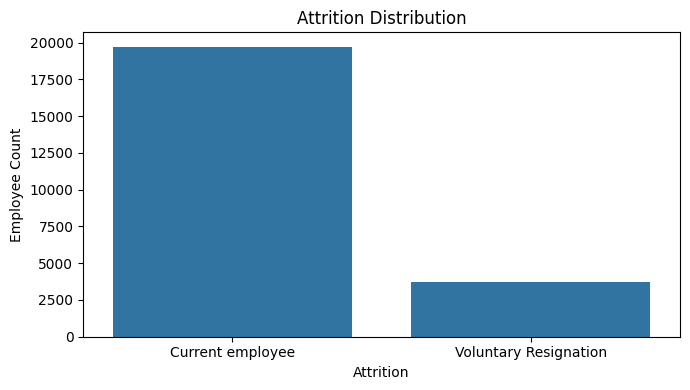

In [ ]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Attrition")
plt.title("Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Employee Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Observed target structure**

The current dataset contains two target classes:

- `Current employee`
- `Voluntary Resignation`

The class distribution should be preserved during the later train/test split using stratification.

## 4. Data Quality Assessment

This section converts the inspection results into an explicit **Data Quality Roadmap**.

A professional cleaning workflow should answer four questions for every variable:

1. What is its analytical role?
2. What quality problem exists, if any?
3. What action is justified?
4. How will the action be validated?

In [ ]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_count": df.nunique(dropna=True)
})

#Constant Columns
constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]

#identifier Columns
identifier_cols = ["EmployeeNumber", "Application ID"]

#target
target_col = "Attrition"

#ordinal Columns
ordinal_cols = [
    "Education",
    "EnvironmentSatisfaction",
    "JobInvolvement",
    "JobLevel",
    "JobSatisfaction",
    "PerformanceRating",
    "RelationshipSatisfaction",
    "StockOptionLevel",
    "WorkLifeBalance"
]

#Numerical Columns
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

#Categorical Columns
categorical_cols = df.select_dtypes(include="object").columns.tolist()

def classify_role(col):
    if col == target_col:
        return "Target"
    if col in identifier_cols:
        return "Identifier"
    if col in constant_cols:
        return "Constant / remove"
    if col in ordinal_cols:
        return "Ordinal feature"
    if col in numeric_cols:
        return "Numerical feature"
    if col in categorical_cols:
        return "Categorical feature"
    return "Review"

quality["analytical_role"] = [classify_role(c) for c in quality.index]

def recommend_action(col):
    if col in constant_cols:
        return "Remove: no information"
    if col in identifier_cols:
        return "Retain for traceability; exclude from ML features"
    if col == target_col:
        return "Validate categories; encode later"
    if quality.loc[col, "missing_count"] > 0:
        return "Investigate missingness before imputation"
    if col in ordinal_cols:
        return "Keep ordered scale; encode according to model needs"
    if col in numeric_cols:
        return "Validate range and investigate outliers"
    if col in categorical_cols:
        return "Validate categories; encode later"
    return "Review"

quality["recommended_action"] = [recommend_action(c) for c in quality.index]
quality

,dtype,missing_count,missing_pct,unique_count,analytical_role,recommended_action
Age,int64,0,0.0,43,Numerical feature,Validate range and investigate outliers
Attrition,object,0,0.0,2,Target,Validate categories; encode later
BusinessTravel,object,0,0.0,3,Categorical feature,Validate categories; encode later
DailyRate,int64,0,0.0,1398,Numerical feature,Validate range and investigate outliers
Department,object,0,0.0,3,Categorical feature,Validate categories; encode later
DistanceFromHome,int64,0,0.0,29,Numerical feature,Validate range and investigate outliers
Education,int64,0,0.0,5,Ordinal feature,Keep ordered scale; encode according to model ...
EducationField,object,0,0.0,6,Categorical feature,Validate categories; encode later
EmployeeCount,int64,0,0.0,1,Constant / remove,Remove: no information
EnvironmentSatisfaction,int64,0,0.0,4,Ordinal feature,Keep ordered scale; encode according to model ...


### Key data-quality findings

The original project inspection showed:

- **23,436 rows and 37 columns** in the raw dataset.
- **No missing values** in the current source file.
- **14 exact duplicate rows**.
- The duplicate `EmployeeNumber` values correspond to those exact duplicate records.
- `EmployeeCount`, `Over18`, and `StandardHours` are constant and therefore provide no analytical information.
- Employee-experience relationships need logical validation.
- High `MonthlyIncome` values require investigation rather than automatic deletion.

## 5. Cleaning the Data

### 5.1 Missing values

In [ ]:
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)

display(missing_report[missing_report["missing_count"] > 0])

total_missing = int(df.isna().sum().sum())
print(f"Total missing values: {total_missing:,}")

if total_missing == 0:
    print("No imputation is required because the current dataset contains zero missing values.")
else:
    print("Missing values exist. They must be investigated before modeling; no blanket imputation is applied here.")

,missing_count,missing_pct


Total missing values: 0
No imputation is required because the current dataset contains zero missing values.


**Decision:** No imputation is performed because the current source contains zero missing values.

This is preferable to inserting artificial values into a dataset that is already complete.

### 5.2 Constant columns

In [ ]:
constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]

constant_summary = pd.DataFrame({
    "column": constant_cols,
    "unique_values": [df[c].unique().tolist() for c in constant_cols]
})

constant_summary

,column,unique_values
0,EmployeeCount,[1]
1,Over18,[Y]
2,StandardHours,[80]


In [ ]:
df = df.drop(columns=constant_cols)

print("Removed constant columns:", constant_cols)
print(f"New shape: {df.shape[0]:,} rows × {df.shape[1]:,} columns")

Removed constant columns: ['EmployeeCount', 'Over18', 'StandardHours']
New shape: 23,436 rows × 34 columns


**Why these columns are removed**

A constant feature has zero variance and cannot distinguish employees or explain differences in attrition. Removing it reduces noise without losing analytical information.

### 5.3 Exact duplicate rows

In [ ]:
duplicate_count = int(df.duplicated().sum())
print(f"Exact duplicate rows: {duplicate_count:,}")

if duplicate_count:
    duplicate_rows = df[df.duplicated(keep=False)].sort_values(
        by=["EmployeeNumber"]
    )
    display(duplicate_rows)
else:
    print("No exact duplicate rows found.")

Exact duplicate rows: 14


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Employee Source,EmployeeNumber,Application ID
3651,42,Current employee,Travel_Rarely,1377,Research & Development,14,1,Life Sciences,1,Female,...,19,3,3,14,3,9,2,LinkedIn,103472,503472
16739,42,Current employee,Travel_Rarely,1377,Research & Development,14,1,Life Sciences,1,Female,...,19,3,3,14,3,9,2,LinkedIn,103472,503472
18386,36,Current employee,Travel_Rarely,157,Research & Development,7,3,Technical Degree,3,Male,...,12,2,3,4,2,3,3,Company Website,107054,507054
7067,36,Current employee,Travel_Rarely,157,Research & Development,7,3,Technical Degree,3,Male,...,12,2,3,4,2,3,3,Company Website,107054,507054
22229,27,Current employee,Travel_Frequently,1118,Research & Development,10,2,Medical,1,Male,...,4,4,3,2,0,2,1,LinkedIn,107487,507487
19045,27,Current employee,Travel_Frequently,1118,Research & Development,10,2,Medical,1,Male,...,4,4,3,2,0,2,1,LinkedIn,107487,507487
17460,51,Voluntary Resignation,Travel_Frequently,1292,Research & Development,12,4,Technical Degree,1,Male,...,33,2,3,9,3,2,2,LinkedIn,109993,509993
22602,51,Voluntary Resignation,Travel_Frequently,1292,Research & Development,12,4,Technical Degree,1,Male,...,33,2,3,9,3,2,2,LinkedIn,109993,509993
3258,44,Current employee,Travel_Rarely,396,Research & Development,13,3,Life Sciences,3,Male,...,18,3,2,8,5,3,3,Company Website,110947,510947
18968,44,Current employee,Travel_Rarely,396,Research & Development,13,3,Life Sciences,3,Male,...,18,3,2,8,5,3,3,Company Website,110947,510947


In [ ]:
if duplicate_count:
    df = df.drop_duplicates().copy()

print("Exact duplicates after treatment:", int(df.duplicated().sum()))

Exact duplicates after treatment: 0


**Decision:** Exact duplicates are removed because they represent repeated copies of the same employee records, not separate observations.

The original inspection found **14 exact duplicates**, and the duplicate `EmployeeNumber` count fell from 14 to 0 after removing those rows.

### 5.4 Duplicate business keys

In [ ]:
duplicate_employee_ids = int(df["EmployeeNumber"].duplicated().sum())
duplicate_application_ids = int(df["Application ID"].duplicated().sum())

print("Duplicate EmployeeNumber values:", duplicate_employee_ids)
print("Duplicate Application ID values:", duplicate_application_ids)

if duplicate_employee_ids:
    display(
        df[df["EmployeeNumber"].duplicated(keep=False)]
        .sort_values("EmployeeNumber")
    )

if duplicate_application_ids:
    display(
        df[df["Application ID"].duplicated(keep=False)]
        .sort_values("Application ID")
    )

Duplicate EmployeeNumber values: 0
Duplicate Application ID values: 0


In [ ]:
# Do not silently delete non-identical records sharing an ID.
if duplicate_employee_ids or duplicate_application_ids:
    raise ValueError(
        "Duplicate business keys remain after exact-duplicate removal. "
        "Investigate them before continuing."
    )

print("Business-key uniqueness validated.")

Business-key uniqueness validated.


**Important methodological correction**

`drop_duplicates()` is not a substitute for duplicate-ID investigation.  
We first remove exact duplicate records, then explicitly verify that the business identifiers are unique. If non-identical records share an identifier, the notebook stops rather than deleting potentially valid employees.

### 5.5 Data-type validation

In [ ]:
# Required numeric fields in this dataset
expected_numeric = [
    "Age", "DailyRate", "DistanceFromHome", "Education",
    "EnvironmentSatisfaction", "HourlyRate", "JobInvolvement",
    "JobLevel", "JobSatisfaction", "MonthlyIncome", "MonthlyRate",
    "NumCompaniesWorked", "PercentSalaryHike", "PerformanceRating",
    "RelationshipSatisfaction", "StockOptionLevel", "TotalWorkingYears",
    "TrainingTimesLastYear", "WorkLifeBalance", "YearsAtCompany",
    "YearsInCurrentRole", "YearsSinceLastPromotion", "YearsWithCurrManager"
]

type_check = pd.DataFrame({
    "column": expected_numeric,
    "dtype": [str(df[c].dtype) for c in expected_numeric],
    "is_numeric": [pd.api.types.is_numeric_dtype(df[c]) for c in expected_numeric]
})

type_check

,column,dtype,is_numeric
0,Age,int64,True
1,DailyRate,int64,True
2,DistanceFromHome,int64,True
3,Education,int64,True
4,EnvironmentSatisfaction,int64,True
5,HourlyRate,int64,True
6,JobInvolvement,int64,True
7,JobLevel,int64,True
8,JobSatisfaction,int64,True
9,MonthlyIncome,int64,True


In [ ]:
non_numeric_expected = type_check.loc[~type_check["is_numeric"], "column"].tolist()

if non_numeric_expected:
    raise TypeError(
        f"These expected numeric columns are not numeric: {non_numeric_expected}"
    )

print("All expected numeric variables have numeric dtypes.")

All expected numeric variables have numeric dtypes.


**Correction to the earlier notebook:** `MonthlyIncome`, `HourlyRate`, `DistanceFromHome`, `PercentSalaryHike`, and `JobSatisfaction` are already numeric in the current source. No unnecessary conversion is performed.

This avoids documenting a transformation that did not actually occur.

### 5.6 Business-rule validation — employee experience

In [ ]:
experience_rules = pd.DataFrame({
    "rule": [
        "YearsAtCompany <= TotalWorkingYears",
        "YearsInCurrentRole <= YearsAtCompany",
        "YearsSinceLastPromotion <= YearsAtCompany",
        "YearsWithCurrManager <= YearsAtCompany"
    ],
    "violations": [
        int((df["YearsAtCompany"] > df["TotalWorkingYears"]).sum()),
        int((df["YearsInCurrentRole"] > df["YearsAtCompany"]).sum()),
        int((df["YearsSinceLastPromotion"] > df["YearsAtCompany"]).sum()),
        int((df["YearsWithCurrManager"] > df["YearsAtCompany"]).sum())
    ]
})

experience_rules

,rule,violations
0,YearsAtCompany <= TotalWorkingYears,0
1,YearsInCurrentRole <= YearsAtCompany,0
2,YearsSinceLastPromotion <= YearsAtCompany,0
3,YearsWithCurrManager <= YearsAtCompany,0


In [ ]:
experience_issues = df[
    (df["YearsAtCompany"] > df["TotalWorkingYears"]) |
    (df["YearsInCurrentRole"] > df["YearsAtCompany"]) |
    (df["YearsSinceLastPromotion"] > df["YearsAtCompany"]) |
    (df["YearsWithCurrManager"] > df["YearsAtCompany"])
].copy()

print(f"Total records violating experience rules: {len(experience_issues):,}")

if not experience_issues.empty:
    display(experience_issues[
        [
            "EmployeeNumber", "TotalWorkingYears", "YearsAtCompany",
            "YearsInCurrentRole", "YearsSinceLastPromotion",
            "YearsWithCurrManager"
        ]
    ])

Total records violating experience rules: 0


**Decision rule:** We do not automatically drop business-rule violations. They must be investigated first because they may be genuine data-entry errors, definition differences, or valid edge cases.

For the current dataset, the validation is expected to return **zero violations**, so no rows are removed on this criterion.

### 5.7 Target validation

In [ ]:
print("Target column:", target_col)
print("Missing target values:", int(df[target_col].isna().sum()))
print("Number of target classes:", df[target_col].nunique(dropna=False))

display(
    df[target_col]
    .value_counts(dropna=False)
    .rename_axis(target_col)
    .reset_index(name="count")
)

assert df[target_col].notna().all(), "Target contains missing values."
assert df[target_col].nunique() == 2, "Expected exactly two target classes."

print("Target validation passed.")

Target column: Attrition
Missing target values: 0
Number of target classes: 2


,Attrition,count
0,Current employee,19701
1,Voluntary Resignation,3721


Target validation passed.


### 5.8 Range & domain validation

In [ ]:
range_checks = {
    "Age": (18, 100),
    "Education": (1, 5),
    "EnvironmentSatisfaction": (1, 4),
    "JobInvolvement": (1, 4),
    "JobLevel": (1, 5),
    "JobSatisfaction": (1, 4),
    "PerformanceRating": (1, 5),
    "RelationshipSatisfaction": (1, 4),
    "StockOptionLevel": (0, 3),
    "WorkLifeBalance": (1, 4)
}

range_results = []
for col, (low, high) in range_checks.items():
    violations = int(((df[col] < low) | (df[col] > high)).sum())
    range_results.append({
        "column": col,
        "expected_min": low,
        "expected_max": high,
        "observed_min": df[col].min(),
        "observed_max": df[col].max(),
        "violations": violations
    })

range_results = pd.DataFrame(range_results)
range_results

,column,expected_min,expected_max,observed_min,observed_max,violations
0,Age,18,100,18,60,0
1,Education,1,5,1,5,0
2,EnvironmentSatisfaction,1,4,1,4,0
3,JobInvolvement,1,4,1,4,0
4,JobLevel,1,5,1,5,0
5,JobSatisfaction,1,4,1,4,0
6,PerformanceRating,1,5,3,4,0
7,RelationshipSatisfaction,1,4,1,4,0
8,StockOptionLevel,0,3,0,3,0
9,WorkLifeBalance,1,4,1,4,0


In [ ]:
if range_results["violations"].sum() == 0:
    print("All defined ordinal/range checks passed.")
else:
    print("Review the rows reported above before modeling.")

All defined ordinal/range checks passed.


### 5.9 Categorical consistency checks

Instead of inventing new categories or silently recoding them, we report the categories actually present in the cleaned data. This makes the notebook auditable and preserves the source terminology.

In [ ]:
categorical_report = []
for col in df.select_dtypes(include="object").columns:
    categorical_report.append({
        "column": col,
        "n_categories": df[col].nunique(dropna=True),
        "missing": int(df[col].isna().sum()),
        "categories": sorted(df[col].dropna().unique().tolist())
    })

categorical_report = pd.DataFrame(categorical_report)
categorical_report

,column,n_categories,missing,categories
0,Attrition,2,0,"[Current employee, Voluntary Resignation]"
1,BusinessTravel,3,0,"[Non-Travel, Travel_Frequently, Travel_Rarely]"
2,Department,3,0,"[Human Resources, Research & Development, Sales]"
3,EducationField,6,0,"[Human Resources, Life Sciences, Marketing, Me..."
4,Gender,2,0,"[Female, Male]"
5,JobRole,9,0,"[Healthcare Representative, Human Resources, L..."
6,MaritalStatus,3,0,"[Divorced, Married, Single]"
7,OverTime,2,0,"[No, Yes]"
8,Employee Source,6,0,"[Campus Hiring, Company Website, Indeed, Linke..."


## 6. Outlier Investigation — IQR Method

### Why we use IQR carefully

The IQR rule identifies values that are statistically distant from the middle 50% of a variable:

**Lower bound = Q1 − 1.5 × IQR**  
**Upper bound = Q3 + 1.5 × IQR**

However:

> **Statistical outlier ≠ invalid record**

HR variables such as salary can legitimately have a long upper tail because employees have different job levels and responsibilities.

Therefore, this section **flags** outliers for investigation and does not delete them automatically.

In [ ]:
# Continuous variables suitable for outlier investigation.
# Ordinal rating variables are intentionally excluded because their small,
# bounded scales make IQR-based deletion inappropriate.
outlier_cols = [
    "Age",
    "DailyRate",
    "DistanceFromHome",
    "HourlyRate",
    "MonthlyIncome",
    "MonthlyRate",
    "NumCompaniesWorked",
    "PercentSalaryHike",
    "TotalWorkingYears",
    "TrainingTimesLastYear",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsSinceLastPromotion",
    "YearsWithCurrManager"
]

outlier_rows = []

for col in outlier_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)

    outlier_rows.append({
        "column": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": int(mask.sum()),
        "outlier_pct": round(mask.mean() * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_rows).sort_values(
    "outlier_pct", ascending=False
)

outlier_summary

,column,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_pct
9,TrainingTimesLastYear,2.00,3.0,1.00,0.500,4.500,3781,16.14
4,MonthlyIncome,3249.00,8018.5,4769.50,-3905.250,15172.750,2848,12.16
7,PercentSalaryHike,12.00,15.0,3.00,7.500,19.500,2627,11.22
10,YearsAtCompany,2.00,7.0,5.00,-5.500,14.500,1012,4.32
11,YearsInCurrentRole,0.00,4.0,4.00,-6.000,10.000,681,2.91
13,YearsWithCurrManager,0.00,4.0,4.00,-6.000,10.000,649,2.77
12,YearsSinceLastPromotion,0.00,4.0,4.00,-6.000,10.000,620,2.65
8,TotalWorkingYears,6.00,17.0,11.00,-10.500,33.500,221,0.94
5,MonthlyRate,8383.75,20789.5,12405.75,-10224.875,39398.125,0,0.00
1,DailyRate,452.00,1154.0,702.00,-601.000,2207.000,0,0.00


### MonthlyIncome — business investigation

In [ ]:
income_q1 = df["MonthlyIncome"].quantile(0.25)
income_q3 = df["MonthlyIncome"].quantile(0.75)
income_iqr = income_q3 - income_q1
income_lower = income_q1 - 1.5 * income_iqr
income_upper = income_q3 + 1.5 * income_iqr

income_outliers = df[
    (df["MonthlyIncome"] < income_lower) |
    (df["MonthlyIncome"] > income_upper)
].copy()

print(f"Q1: {income_q1:,.2f}")
print(f"Q3: {income_q3:,.2f}")
print(f"IQR: {income_iqr:,.2f}")
print(f"Lower bound: {income_lower:,.2f}")
print(f"Upper bound: {income_upper:,.2f}")
print(f"Outlier rows: {len(income_outliers):,}")
print(f"Outlier percentage: {len(income_outliers) / len(df) * 100:.2f}%")

Q1: 3,249.00
Q3: 8,018.50
IQR: 4,769.50
Lower bound: -3,905.25
Upper bound: 15,172.75
Outlier rows: 2,848
Outlier percentage: 12.16%


In [ ]:
# Inspect the high-income tail with business context.
display(
    df.nlargest(10, "MonthlyIncome")[
        [
            "EmployeeNumber", "Age", "Department", "JobRole",
            "MonthlyIncome", "JobLevel", "TotalWorkingYears",
            "YearsAtCompany", "Attrition"
        ]
    ]
)

,EmployeeNumber,Age,Department,JobRole,MonthlyIncome,JobLevel,TotalWorkingYears,YearsAtCompany,Attrition
3,117076,35,Sales,Manager,19999,5,11,10,Voluntary Resignation
192,116385,39,Research & Development,Manager,19999,5,15,6,Current employee
215,119664,41,Sales,Manager,19999,5,14,10,Current employee
233,106999,44,Research & Development,Manager,19999,5,20,12,Voluntary Resignation
343,109903,37,Sales,Manager,19999,5,7,4,Voluntary Resignation
346,118833,51,Research & Development,Research Director,19999,5,25,1,Current employee
347,123209,28,Research & Development,Manager,19999,5,4,2,Current employee
378,117675,41,Research & Development,Manager,19999,5,21,14,Current employee
533,102036,44,Sales,Manager,19999,5,13,0,Voluntary Resignation
541,102665,34,Research & Development,Research Director,19999,5,7,2,Current employee


In [ ]:
max_income = df["MonthlyIncome"].max()

print(f"Maximum MonthlyIncome: {max_income:,.0f}")
print(
    f"Employees at maximum MonthlyIncome: "
    f"{int((df['MonthlyIncome'] == max_income).sum()):,}"
)

display(
    df.loc[df["MonthlyIncome"] == max_income, "JobRole"]
      .value_counts()
      .rename("count")
      .to_frame()
)

display(
    df.loc[df["MonthlyIncome"] == max_income, "JobLevel"]
      .value_counts()
      .rename("count")
      .to_frame()
)

Maximum MonthlyIncome: 19,999
Employees at maximum MonthlyIncome: 446


,count
JobRole,
Manager,345
Research Director,101


,count
JobLevel,
5,446


### Outlier decision

The previous analysis showed that the maximum `MonthlyIncome` value of **19,999** is associated with `JobLevel = 5` and the senior roles `Manager` and `Research Director`.

This provides business context for the high values. They should therefore **not be deleted simply because the IQR rule flags them**.

The same principle applies to other legitimate high-value employees: investigate first, preserve valid observations, and consider robust modeling or transformation later if required.

## 7. Final Data Quality Validation

The final validation compares the raw snapshot with the cleaned dataframe.

A good cleaning process should make every row/column change explainable.

In [ ]:
final_validation = pd.DataFrame({
    "Before": [
        df_raw.shape[0],
        df_raw.shape[1],
        int(df_raw.isna().sum().sum()),
        int(df_raw.duplicated().sum()),
        int(df_raw["EmployeeNumber"].duplicated().sum()),
        int(df_raw["Application ID"].duplicated().sum())
    ],
    "After": [
        df.shape[0],
        df.shape[1],
        int(df.isna().sum().sum()),
        int(df.duplicated().sum()),
        int(df["EmployeeNumber"].duplicated().sum()),
        int(df["Application ID"].duplicated().sum())
    ]
}, index=[
    "Rows",
    "Columns",
    "Total missing values",
    "Full duplicate rows",
    "Duplicate EmployeeNumber",
    "Duplicate Application ID"
])

final_validation

,Before,After
Rows,23436,23422
Columns,37,34
Total missing values,0,0
Full duplicate rows,14,0
Duplicate EmployeeNumber,14,0
Duplicate Application ID,14,0


### Rows removed — explicit reconciliation

In [ ]:
rows_removed = len(df_raw) - len(df)

print(f"Rows removed: {rows_removed:,}")
print("Expected reason: exact duplicate rows only.")

if rows_removed != int(df_raw.duplicated().sum()):
    print(
        "Review required: row removal is not explained solely by the raw "
        "exact-duplicate count."
    )
else:
    print("Row-removal reconciliation passed.")

Rows removed: 14
Expected reason: exact duplicate rows only.
Row-removal reconciliation passed.


### Final assertions

In [ ]:
# Completeness
assert df.isna().sum().sum() == 0, "Missing values remain."

# Duplicate records and business keys
assert df.duplicated().sum() == 0, "Exact duplicate rows remain."
assert df["EmployeeNumber"].is_unique, "EmployeeNumber is not unique."
assert df["Application ID"].is_unique, "Application ID is not unique."

# Target
assert df["Attrition"].notna().all(), "Target contains missing values."
assert df["Attrition"].nunique() == 2, "Unexpected target cardinality."

# Experience logic
assert (df["YearsAtCompany"] <= df["TotalWorkingYears"]).all()
assert (df["YearsInCurrentRole"] <= df["YearsAtCompany"]).all()
assert (df["YearsSinceLastPromotion"] <= df["YearsAtCompany"]).all()
assert (df["YearsWithCurrManager"] <= df["YearsAtCompany"]).all()

# Constant columns should no longer exist
assert all(df[c].nunique(dropna=False) > 1 for c in df.columns)

print("✅ All final data-quality assertions passed.")

✅ All final data-quality assertions passed.


## 8. Final Analytical Dataset

In [ ]:
print("Final shape:", df.shape)

final_profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
    "role": [classify_role(c) for c in df.columns]
})

final_profile

Final shape: (23422, 34)


,dtype,missing,unique,role
Age,int64,0,43,Numerical feature
Attrition,object,0,2,Target
BusinessTravel,object,0,3,Categorical feature
DailyRate,int64,0,1398,Numerical feature
Department,object,0,3,Categorical feature
DistanceFromHome,int64,0,29,Numerical feature
Education,int64,0,5,Ordinal feature
EducationField,object,0,6,Categorical feature
EnvironmentSatisfaction,int64,0,4,Ordinal feature
Gender,object,0,2,Categorical feature


### What is ready for the next stage?

The cleaned dataset is now suitable for:

1. Exploratory Data Analysis (EDA)
2. Feature engineering
3. Train/test splitting
4. Encoding categorical variables
5. Scaling where model-dependent
6. Imbalance-aware model training
7. Model evaluation and explainability

### Important modeling note

`EmployeeNumber` and `Application ID` are identifiers. They remain in this cleaned dataset for traceability, but they **must be excluded from ML features** to avoid treating identifiers as predictive information.

Similarly, preprocessing parameters such as scaling and imputation—if needed later—must be fitted on the training data only to prevent data leakage.

## 9. Export the Clean Dataset

In [ ]:
OUTPUT_PATH = "/content/drive/MyDrive/Final Project/IBM_HR_CLEANED.csv"

df.to_csv(OUTPUT_PATH, index=False)

print(f"Clean dataset exported successfully to:\n{OUTPUT_PATH}")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

Clean dataset exported successfully to:
/content/drive/MyDrive/Final Project/IBM_HR_CLEANED.csv
Rows: 23,422
Columns: 34


## 10. Executive Summary of the Cleaning Stage

### Before cleaning
- **23,436 rows**
- **37 columns**
- No missing values in the current source
- 14 exact duplicate rows
- 3 constant columns

### Cleaning decisions
- Preserved a raw copy (`df_raw`).
- Removed exact duplicate records.
- Removed constant columns because they contain no information.
- Verified business-key uniqueness after duplicate removal.
- Verified numeric data types rather than performing unnecessary conversions.
- Validated employee-experience relationships.
- Validated the binary target.
- Investigated outliers using IQR.
- **Did not delete valid salary outliers automatically.**

### Expected final state
- **23,422 rows**
- **34 columns**
- **0 missing values**
- **0 exact duplicate rows**
- **0 duplicate EmployeeNumber values**
- **0 duplicate Application ID values**
- Business-rule checks passed

> **Conclusion:** The dataset is now documented, validated, and ready for the project's EDA and machine-learning preparation stage.